In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.distributions import gaussian
from src.gmm import GMM

### **Part 1: Lab 6 Gaussian Mixture Data**

In [2]:
n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([7.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),  # bottom: full
    np.eye(2),                           # middle: isotropic
    np.diag([1.5, 0.5])                  # top: diagonal
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]
class_covariances = [covariances, covariances_2]
covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [3]:
# GMM data generation - 2 GMMs each has 3 gaussian components.

class_samples = []
class_component_labels = []

for class_index in range(2):
    rng = np.random.default_rng(42 + class_index)
    labels = rng.choice(K, size=n, p=weights)
    X = np.zeros((n, 2))

    for k in range(K):
        selected = labels == k
        component_n = np.sum(selected)

        eigenvalues, eigenvectors = np.linalg.eigh(class_covariances[class_index][k])
        cov_sqrt = eigenvectors @ np.diag(np.sqrt(eigenvalues)) @ eigenvectors.T

        standard_samples = np.column_stack((
            gaussian(0, 1, component_n, rng),
            gaussian(0, 1, component_n, rng)
        ))
        X[selected] = standard_samples @ cov_sqrt.T + class_means[class_index][k]

    class_samples.append(X)
    class_component_labels.append(labels)

print([sample.shape for sample in class_samples])

[(5000, 2), (5000, 2)]


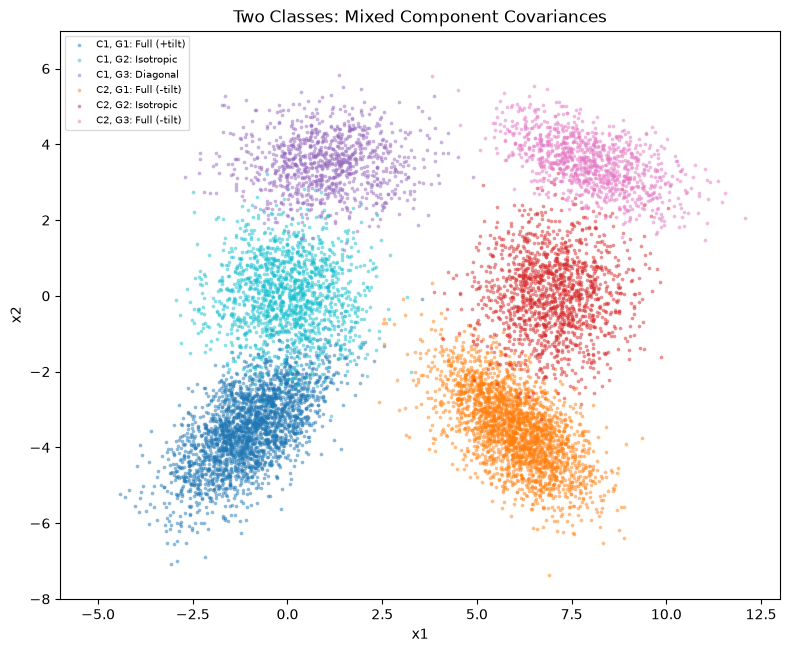

In [4]:
component_colors = [
    ["tab:blue", "tab:cyan", "tab:purple"],
    ["tab:orange", "tab:red", "tab:pink"]
]

plt.figure(figsize=(8, 7))
for class_index in range(2):
    for k in range(K):
        sample = class_samples[class_index][class_component_labels[class_index] == k]
        plt.scatter(
            sample[:, 0], sample[:, 1], s=7, alpha=0.5, linewidths=0,
            color=component_colors[class_index][k],
            label=f"C{class_index + 1}, G{k + 1}: {covariance_names[class_index][k]}"
        )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Two Classes: Mixed Component Covariances")
plt.legend(fontsize=7, framealpha=0.7)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.show()

In [5]:
# train and test split - 80% train and 20% test

train_class_samples = []
test_class_samples = []

rng = np.random.default_rng(44)
train_end = int(0.8 * n)

for samples in class_samples:
    shuffled = samples[rng.permutation(n)]
    train_class_samples.append(shuffled[:train_end])
    test_class_samples.append(shuffled[train_end:])

### **GMM Training Using EM**

In [6]:
class_models = []

for class_index, samples in enumerate(train_class_samples):
    model = GMM(K=K)
    model.fit(samples)
    class_models.append(model)
    print(f"Class {class_index + 1} weights:\n{model.weights}")
    print(f"Class {class_index + 1} means:\n{model.means}")
    print(f"Class {class_index + 1} covariances:\n{model.covariances}")
    print("EM iterations:", len(model.log_likelihoods))

Class 1 weights:
[0.50389071 0.19763855 0.29847075]
Class 1 means:
[[-0.98323855 -3.47590008]
 [ 1.02314468  3.49218403]
 [-0.0141934   0.05306165]]
Class 1 covariances:
[[[1.05290675 0.65803162]
  [0.65803162 1.02129904]]

 [[1.4737598  0.01393159]
  [0.01393159 0.52942579]]

 [[1.02305286 0.01029905]
  [0.01029905 1.05674572]]]
EM iterations: 26
Class 2 weights:
[0.29636944 0.49160402 0.21202654]
Class 2 means:
[[ 6.99374526  0.04755074]
 [ 6.00787549 -3.51035862]
 [ 7.98202528  3.50794491]]
Class 2 covariances:
[[[ 0.97582114  0.03623115]
  [ 0.03623115  1.1194619 ]]

 [[ 1.04733302 -0.63272774]
  [-0.63272774  1.02246075]]

 [[ 1.430863   -0.48580749]
  [-0.48580749  0.4910973 ]]]
EM iterations: 13


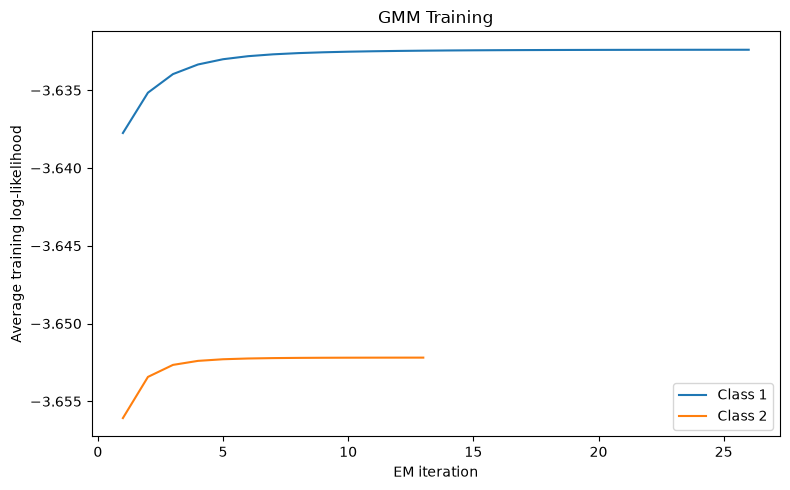

In [7]:
plt.figure(figsize=(8, 5))
for class_index, model in enumerate(class_models):
    iterations = np.arange(1, len(model.log_likelihoods) + 1)
    plt.plot(iterations, model.log_likelihoods, label=f"Class {class_index + 1}")

plt.xlabel("EM iteration")
plt.ylabel("Average training log-likelihood")
plt.title("GMM Training")
plt.legend()
plt.tight_layout()
plt.show()

### **Test Classification Using GMM Likelihoods**

In [8]:
# equal class priors: choose the class with the highest log-likelihood

test_class_predictions = []

for samples in test_class_samples:
    scores = np.column_stack([model.score_samples(samples) for model in class_models])
    predictions = np.argmax(scores, axis=1) + 1
    test_class_predictions.append(predictions)

In [9]:
# rows: true class, columns: predicted class
confusion_matrix = np.zeros((2, 2), dtype=int)

for true_class, predictions in enumerate(test_class_predictions):
    for predicted_class in predictions:
        confusion_matrix[true_class, predicted_class - 1] += 1

print("Confusion matrix:\n", confusion_matrix)
print("Accuracy:", np.trace(confusion_matrix) / confusion_matrix.sum())

Confusion matrix:
 [[999   1]
 [  1 999]]
Accuracy: 0.999


### **Decision Boundary Between the Two Classes**

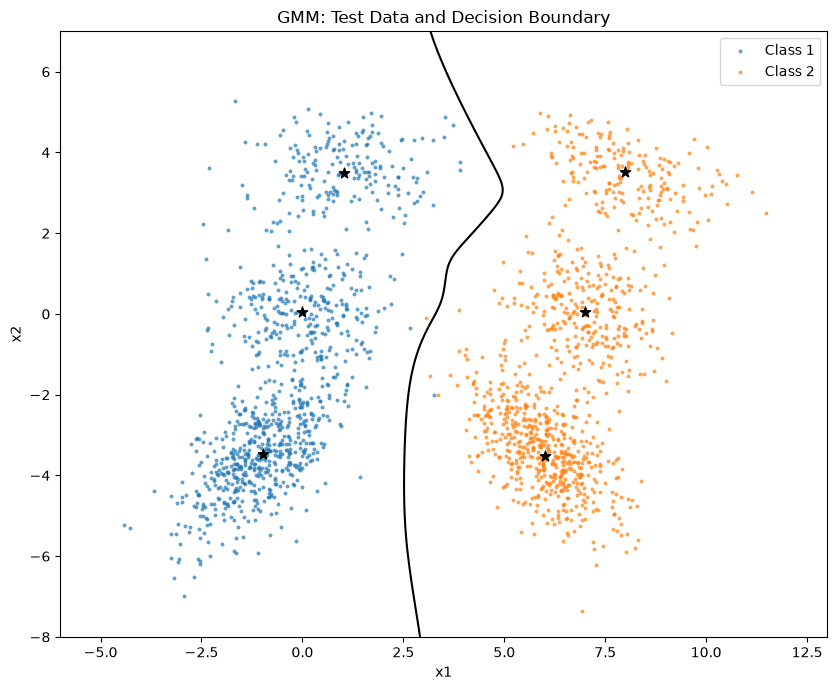

In [10]:
x_values = np.linspace(-6, 13, 200)
y_values = np.linspace(-8, 7, 200)
x_grid, y_grid = np.meshgrid(x_values, y_values)
grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))
class_scores = []

for model in class_models:
    scores = model.score_samples(grid_points).reshape(x_grid.shape)
    class_scores.append(scores)

plt.figure(figsize=(9, 7))
for class_index, samples in enumerate(test_class_samples):
    plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.7, linewidths=0,
                color=component_colors[class_index][0], label=f"Class {class_index + 1}")
    plt.scatter(class_models[class_index].means[:, 0], class_models[class_index].means[:, 1],
                marker="*", s=60, color="black")

plt.contour(x_grid, y_grid, class_scores[0] - class_scores[1],
            levels=[0], colors="black")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("GMM: Test Data and Decision Boundary")
plt.legend(fontsize=10)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.show()

### **Part 2: MNIST Digits 2, 3, and 9**

In [11]:
import os
from PIL import Image

digits = np.array([2, 3, 9])


def load_digit_images(folder):
    class_images = []
    for digit in digits:
        images = []
        digit_folder = f"{folder}/{digit}"
        for filename in sorted(os.listdir(digit_folder)):
            if filename.endswith(".png"):
                with Image.open(f"{digit_folder}/{filename}") as image:
                    images.append(np.array(image.convert("L")))
        class_images.append(np.array(images, dtype=float) / 255.0)
    return class_images


mnist_train_images = load_digit_images("./data/train")
mnist_dev_images = load_digit_images("./data/dev")

for digit, train_images, dev_images in zip(digits, mnist_train_images, mnist_dev_images):
    print(f"Digit {digit}: train {train_images.shape}, dev {dev_images.shape}")

Digit 2: train (4762, 28, 28), dev (1196, 28, 28)
Digit 3: train (4886, 28, 28), dev (1245, 28, 28)
Digit 9: train (4776, 28, 28), dev (1173, 28, 28)


### **Original Images and 784 Pixel Features**

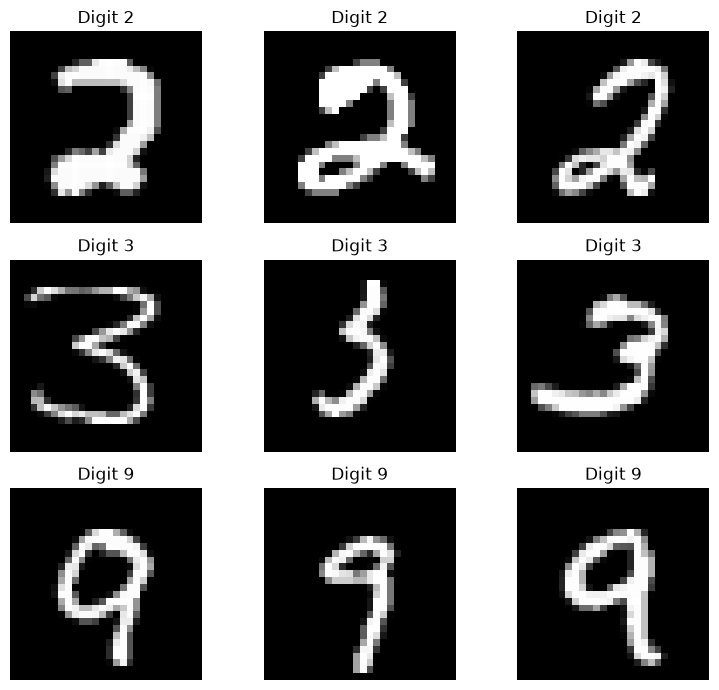

In [12]:
def pixel_features(images):
    return images.reshape(len(images), 784)


mnist_train = [pixel_features(images) for images in mnist_train_images]
mnist_dev = [pixel_features(images) for images in mnist_dev_images]

plt.figure(figsize=(8, 7))
for class_index, digit in enumerate(digits):
    for i in range(3):
        plt.subplot(3, 3, class_index * 3 + i + 1)
        plt.imshow(mnist_train_images[class_index][i], cmap="gray", vmin=0, vmax=1)
        plt.title(f"Digit {digit}")
        plt.axis("off")

plt.tight_layout()
plt.show()

### **Choose the Component Count Using Development Data**

In [13]:
component_counts = [3, 5, 8]
dev_results = []
best_dev_accuracy = -1
best_K = None
mnist_models = None

for digit_K in component_counts:
    models = []
    for digit, samples in zip(digits, mnist_train):
        model = GMM(K=digit_K, reg=1e-3, max_iter=200, tol=1e-4)
        model.fit(samples)
        models.append(model)
        print(f"K={digit_K}, digit {digit}: {len(model.log_likelihoods)} EM iterations")
        if len(model.log_likelihoods) == model.max_iter:
            print("  Reached the iteration limit; convergence is not guaranteed.")

    dev_confusion = np.zeros((3, 3), dtype=int)
    for true_class, samples in enumerate(mnist_dev):
        scores = np.column_stack([model.score_samples(samples) for model in models])
        predictions = np.argmax(scores, axis=1)
        for predicted_class in predictions:
            dev_confusion[true_class, predicted_class] += 1

    dev_accuracy = np.trace(dev_confusion) / dev_confusion.sum()
    dev_results.append((digit_K, dev_accuracy))
    print(f"K={digit_K}: development accuracy = {dev_accuracy:.4%}\n")

    if dev_accuracy > best_dev_accuracy:
        best_dev_accuracy = dev_accuracy
        best_K = digit_K
        mnist_models = models

print("Selected K:", best_K)
print(f"Best development accuracy: {best_dev_accuracy:.4%}")

K=3, digit 2: 17 EM iterations
K=3, digit 3: 25 EM iterations
K=3, digit 9: 38 EM iterations
K=3: development accuracy = 96.6519%

K=5, digit 2: 9 EM iterations
K=5, digit 3: 14 EM iterations
K=5, digit 9: 28 EM iterations
K=5: development accuracy = 96.7626%

K=8, digit 2: 2 EM iterations
K=8, digit 3: 17 EM iterations
K=8, digit 9: 23 EM iterations
K=8: development accuracy = 97.5097%

Selected K: 8
Best development accuracy: 97.5097%


### **Learned Gaussian Component Means**

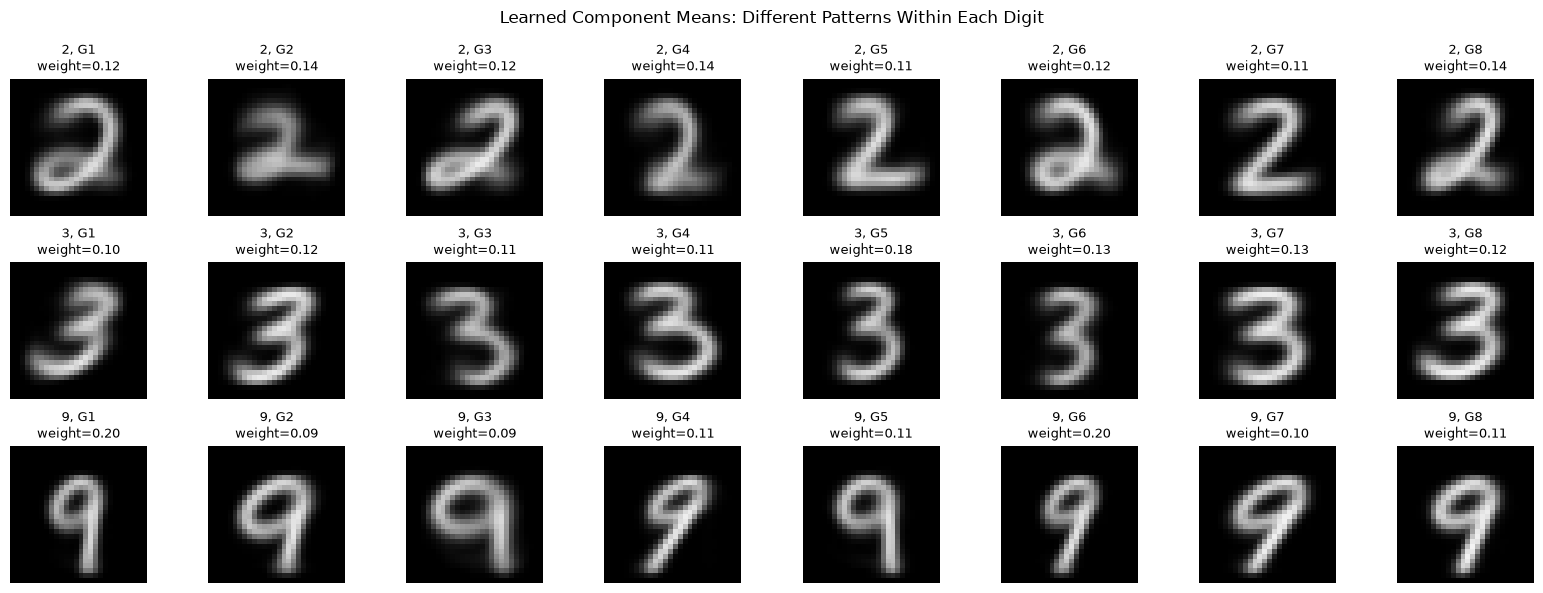

In [14]:
plt.figure(figsize=(2 * best_K, 6))
for class_index, (digit, model) in enumerate(zip(digits, mnist_models)):
    for k in range(best_K):
        plt.subplot(3, best_K, class_index * best_K + k + 1)
        plt.imshow(model.means[k].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        plt.title(f"{digit}, G{k + 1}\nweight={model.weights[k]:.2f}", fontsize=9)
        plt.axis("off")

plt.suptitle("Learned Component Means: Different Patterns Within Each Digit")
plt.tight_layout()
plt.show()

### **Test Classification**

In [15]:
# Load test images only after selecting K.
mnist_test_images = load_digit_images("./data/test")
mnist_test = [pixel_features(images) for images in mnist_test_images]

mnist_scores = []
mnist_predictions = []
mnist_confusion = np.zeros((3, 3), dtype=int)

for true_class, samples in enumerate(mnist_test):
    scores = np.column_stack([model.score_samples(samples) for model in mnist_models])
    predictions = np.argmax(scores, axis=1)
    mnist_scores.append(scores)
    mnist_predictions.append(predictions)

    for predicted_class in predictions:
        mnist_confusion[true_class, predicted_class] += 1

print("Digit order:", digits)
print("Confusion matrix (rows: true, columns: predicted):\n", mnist_confusion)
mnist_accuracy = np.trace(mnist_confusion) / mnist_confusion.sum()
print(f"Test accuracy: {mnist_accuracy:.4%}")

for class_index, digit in enumerate(digits):
    recall = mnist_confusion[class_index, class_index] / mnist_confusion[class_index].sum()
    print(f"Digit {digit}: recall = {recall:.4%}")

Digit order: [2 3 9]
Confusion matrix (rows: true, columns: predicted):
 [[1016   13    3]
 [   9  994    7]
 [   9   33  967]]
Test accuracy: 97.5746%
Digit 2: recall = 98.4496%
Digit 3: recall = 98.4158%
Digit 9: recall = 95.8375%


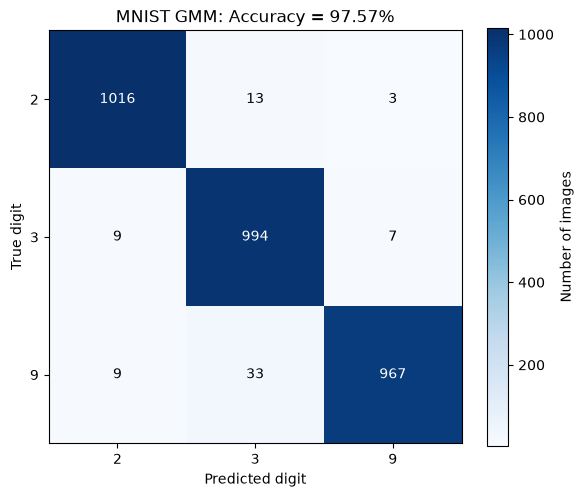

In [16]:
plt.figure(figsize=(6, 5))
plt.imshow(mnist_confusion, cmap="Blues")
plt.xticks(range(3), digits)
plt.yticks(range(3), digits)
for i in range(3):
    for j in range(3):
        plt.text(j, i, str(mnist_confusion[i, j]), ha="center", va="center",
                 color="white" if mnist_confusion[i, j] > mnist_confusion.max() / 2 else "black")
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.title(f"MNIST GMM: Accuracy = {mnist_accuracy:.2%}")
plt.colorbar(label="Number of images")
plt.tight_layout()
plt.show()

### **Misclassified Test Images**

2 -> 3: 13 errors
2 -> 9: 3 errors
3 -> 2: 9 errors
3 -> 9: 7 errors
9 -> 2: 9 errors
9 -> 3: 33 errors


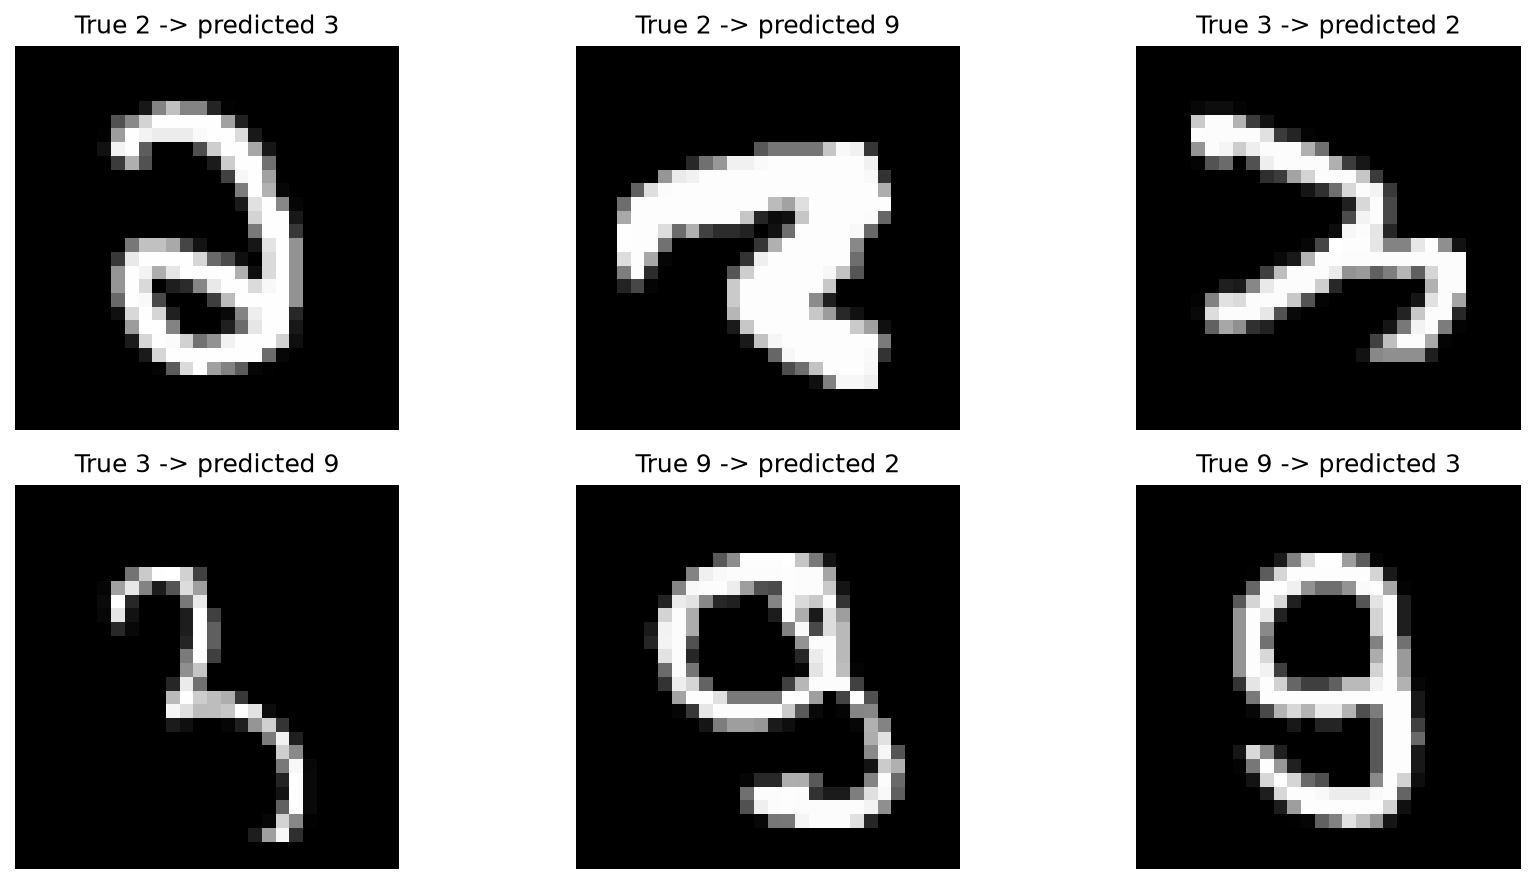

In [18]:
# Show the first misclassified image for each true/predicted digit pair.
error_examples = []
for true_class in range(3):
    for predicted_class in range(3):
        if true_class == predicted_class:
            continue
        indices = np.where(mnist_predictions[true_class] == predicted_class)[0]
        if len(indices) > 0:
            error_examples.append((true_class, predicted_class, indices[0]))
            print(f"{digits[true_class]} -> {digits[predicted_class]}: {len(indices)} errors")

if len(error_examples) > 0:
    rows = (len(error_examples) + 2) // 3
    plt.figure(figsize=(12, 3 * rows))
    for i, (true_class, predicted_class, image_index) in enumerate(error_examples):
        plt.subplot(rows, 3, i + 1)
        plt.imshow(mnist_test_images[true_class][image_index], cmap="gray", vmin=0, vmax=1)
        plt.title(f"True {digits[true_class]} -> predicted {digits[predicted_class]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified test images.")